# Task 60. Exercise on Linguistics using Machine learning in python

In [1]:
# ===== Setup: download the NLTK data used in this notebook =====
import nltk

for resource in ['punkt', 'punkt_tab', 'stopwords', 'wordnet', 'omw-1.4',
                 'averaged_perceptron_tagger', 'averaged_perceptron_tagger_eng',
                 'maxent_ne_chunker', 'maxent_ne_chunker_tab', 'words', 'names', 'movie_reviews',
                 'tagsets', 'tagsets_json']:
    nltk.download(resource, quiet=True)

In [2]:
# ===== Sample text =====
text = """Natural language processing is a field of artificial intelligence that helps computers
understand human language. Pratik and Roberto wrote a tutorial in July 2020 at Towards AI in
San Francisco. They explained how computers read text, split it into words, and find the
meaning of sentences. Machine learning models learn patterns from large amounts of text data.
Today, NLP powers search engines, chatbots, translation tools and voice assistants like Siri."""
print(text)

Natural language processing is a field of artificial intelligence that helps computers
understand human language. Pratik and Roberto wrote a tutorial in July 2020 at Towards AI in
San Francisco. They explained how computers read text, split it into words, and find the
meaning of sentences. Machine learning models learn patterns from large amounts of text data.
Today, NLP powers search engines, chatbots, translation tools and voice assistants like Siri.


In [3]:
# ===== Tokenization: sentences =====
from nltk.tokenize import sent_tokenize, word_tokenize

sentences = sent_tokenize(text)
print(len(sentences), "sentences")
for s in sentences:
    print("-", s)

5 sentences
- Natural language processing is a field of artificial intelligence that helps computers
understand human language.
- Pratik and Roberto wrote a tutorial in July 2020 at Towards AI in
San Francisco.
- They explained how computers read text, split it into words, and find the
meaning of sentences.
- Machine learning models learn patterns from large amounts of text data.
- Today, NLP powers search engines, chatbots, translation tools and voice assistants like Siri.


In [4]:
# ===== Tokenization: words =====
words = word_tokenize(text)
print(len(words), "tokens")
print(words)

80 tokens
['Natural', 'language', 'processing', 'is', 'a', 'field', 'of', 'artificial', 'intelligence', 'that', 'helps', 'computers', 'understand', 'human', 'language', '.', 'Pratik', 'and', 'Roberto', 'wrote', 'a', 'tutorial', 'in', 'July', '2020', 'at', 'Towards', 'AI', 'in', 'San', 'Francisco', '.', 'They', 'explained', 'how', 'computers', 'read', 'text', ',', 'split', 'it', 'into', 'words', ',', 'and', 'find', 'the', 'meaning', 'of', 'sentences', '.', 'Machine', 'learning', 'models', 'learn', 'patterns', 'from', 'large', 'amounts', 'of', 'text', 'data', '.', 'Today', ',', 'NLP', 'powers', 'search', 'engines', ',', 'chatbots', ',', 'translation', 'tools', 'and', 'voice', 'assistants', 'like', 'Siri', '.']


In [5]:
# ===== Frequency distribution =====
from nltk.probability import FreqDist

fdist = FreqDist(words)
fdist.most_common(10)

[('.', 5),
 (',', 5),
 ('of', 3),
 ('and', 3),
 ('language', 2),
 ('a', 2),
 ('computers', 2),
 ('in', 2),
 ('text', 2),
 ('Natural', 1)]

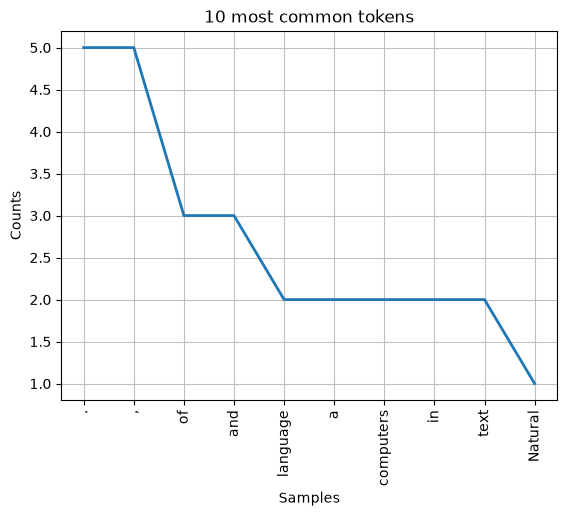

In [6]:
import matplotlib.pyplot as plt

fdist.plot(10, title='10 most common tokens')
plt.show()

In [7]:
# ===== Removing punctuation =====
words_no_punc = [w.lower() for w in words if w.isalpha()]
print(words_no_punc)

['natural', 'language', 'processing', 'is', 'a', 'field', 'of', 'artificial', 'intelligence', 'that', 'helps', 'computers', 'understand', 'human', 'language', 'pratik', 'and', 'roberto', 'wrote', 'a', 'tutorial', 'in', 'july', 'at', 'towards', 'ai', 'in', 'san', 'francisco', 'they', 'explained', 'how', 'computers', 'read', 'text', 'split', 'it', 'into', 'words', 'and', 'find', 'the', 'meaning', 'of', 'sentences', 'machine', 'learning', 'models', 'learn', 'patterns', 'from', 'large', 'amounts', 'of', 'text', 'data', 'today', 'nlp', 'powers', 'search', 'engines', 'chatbots', 'translation', 'tools', 'and', 'voice', 'assistants', 'like', 'siri']


In [8]:
# ===== Removing stop words =====
from nltk.corpus import stopwords

stop_words = set(stopwords.words('english'))
print(len(stop_words), "English stop words, e.g.", sorted(stop_words)[:15])

clean_words = [w for w in words_no_punc if w not in stop_words]
print(clean_words)

198 English stop words, e.g. ['a', 'about', 'above', 'after', 'again', 'against', 'ain', 'all', 'am', 'an', 'and', 'any', 'are', 'aren', "aren't"]
['natural', 'language', 'processing', 'field', 'artificial', 'intelligence', 'helps', 'computers', 'understand', 'human', 'language', 'pratik', 'roberto', 'wrote', 'tutorial', 'july', 'towards', 'ai', 'san', 'francisco', 'explained', 'computers', 'read', 'text', 'split', 'words', 'find', 'meaning', 'sentences', 'machine', 'learning', 'models', 'learn', 'patterns', 'large', 'amounts', 'text', 'data', 'today', 'nlp', 'powers', 'search', 'engines', 'chatbots', 'translation', 'tools', 'voice', 'assistants', 'like', 'siri']


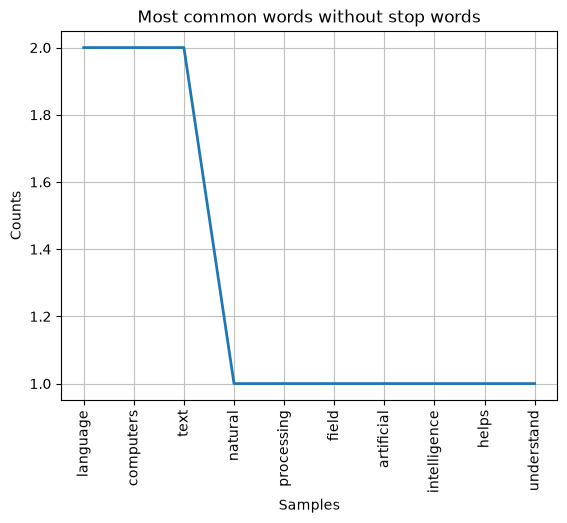

In [9]:
FreqDist(clean_words).plot(10, title='Most common words without stop words')
plt.show()

In [10]:
# ===== Stemming =====
from nltk.stem import PorterStemmer, SnowballStemmer

porter = PorterStemmer()
snowball = SnowballStemmer('english')

for w in ['studies', 'studying', 'computers', 'computation', 'learning', 'happily', 'running']:
    print(f"{w:12} porter: {porter.stem(w):10} snowball: {snowball.stem(w)}")

studies      porter: studi      snowball: studi
studying     porter: studi      snowball: studi
computers    porter: comput     snowball: comput
computation  porter: comput     snowball: comput
learning     porter: learn      snowball: learn
happily      porter: happili    snowball: happili
running      porter: run        snowball: run


In [11]:
# ===== Lemmatization =====
from nltk.stem import WordNetLemmatizer

lemmatizer = WordNetLemmatizer()
for w in ['studies', 'studying', 'computers', 'better', 'geese', 'running']:
    print(f"{w:10} noun: {lemmatizer.lemmatize(w):10} verb: {lemmatizer.lemmatize(w, pos='v'):10} adjective: {lemmatizer.lemmatize(w, pos='a')}")

studies    noun: study      verb: study      adjective: studies
studying   noun: studying   verb: study      adjective: studying
computers  noun: computer   verb: computers  adjective: computers
better     noun: better     verb: better     adjective: good
geese      noun: goose      verb: geese      adjective: geese
running    noun: running    verb: run        adjective: running


In [12]:
# ===== Stemming vs. lemmatization =====
for w in ['studies', 'feet', 'corpora', 'rocks', 'cries']:
    print(f"{w:8} stem: {porter.stem(w):8} lemma: {lemmatizer.lemmatize(w)}")

studies  stem: studi    lemma: study
feet     stem: feet     lemma: foot
corpora  stem: corpora  lemma: corpus
rocks    stem: rock     lemma: rock
cries    stem: cri      lemma: cry


In [13]:
# ===== Part of Speech (PoS) tagging =====
from nltk import pos_tag

tagged = pos_tag(word_tokenize(sentences[1]))
tagged

[('Pratik', 'NNP'),
 ('and', 'CC'),
 ('Roberto', 'NNP'),
 ('wrote', 'VBD'),
 ('a', 'DT'),
 ('tutorial', 'NN'),
 ('in', 'IN'),
 ('July', 'NNP'),
 ('2020', 'CD'),
 ('at', 'IN'),
 ('Towards', 'NNP'),
 ('AI', 'NNP'),
 ('in', 'IN'),
 ('San', 'NNP'),
 ('Francisco', 'NNP'),
 ('.', '.')]

In [14]:
# meaning of a few tags
for tag in ['NNP', 'VBD', 'IN', 'CD', 'DT', 'NN']:
    nltk.help.upenn_tagset(tag)

NNP: noun, proper, singular
    Motown Venneboerger Czestochwa Ranzer Conchita Trumplane Christos
    Oceanside Escobar Kreisler Sawyer Cougar Yvette Ervin ODI Darryl CTCA
    Shannon A.K.C. Meltex Liverpool ...
VBD: verb, past tense
    dipped pleaded swiped regummed soaked tidied convened halted registered
    cushioned exacted snubbed strode aimed adopted belied figgered
    speculated wore appreciated contemplated ...


IN: preposition or conjunction, subordinating
    astride among uppon whether out inside pro despite on by throughout
    below within for towards near behind atop around if like until below
    next into if beside ...
CD: numeral, cardinal
    mid-1890 nine-thirty forty-two one-tenth ten million 0.5 one forty-
    seven 1987 twenty '79 zero two 78-degrees eighty-four IX '60s .025
    fifteen 271,124 dozen quintillion DM2,000 ...


DT: determiner
    all an another any both del each either every half la many much nary
    neither no some such that the them these this those
NN: noun, common, singular or mass
    common-carrier cabbage knuckle-duster Casino afghan shed thermostat
    investment slide humour falloff slick wind hyena override subhumanity
    machinist ...
